# Homework - Performance Evaluation of Diffusion models
In this homework, you will conduct a performance comparison between two popular diffusion models: Denoising Diffusion Probabilistic Models ([DDPM](https://arxiv.org/pdf/2006.11239)) and Denoising Diffusion Implicit Models ([DDIM](https://arxiv.org/pdf/2010.02502)). Your task is to evaluate and compare the efficacy of these models in generating high-quality synthetic data, focusing on aspects such as image quality, computational efficiency, and training stability. You will implement both models, apply them to a common dataset, and analyze their performance using metrics like FID (Fréchet Inception Distance). The goal is to understand the strengths and weaknesses of DDPM and DDIM, providing insights into how their differing approaches to diffusion and denoising affect overall model performance.

## Instructions
Submit your assignment as Jupter notebook with all relevant execution outputs and plots visible. Please clearly indicate the relevant steps in your code using comments, such as data pre-processing, model definition, model training. Partial grades can be given for imcomplete results when the steps are clearly marked.

1. Ensure you have the cloned the [course repository](https://github.com/lydiaYchen/25MSGAI).
2. Open the interactive notebook version (homework_diffusion.ipynb) of homework from your local clone.
3. Complete the homework by filling the code cell and answers. Please ensure that the changes are saved.
4. Upload the notebook to the assignment in the system.

Please submit your assignment as a Jupyter Notebook, ensuring that all relevant execution outputs and plots are visible. Your notebook should include a clear and organized structure, with comments for each major step of the assignment. For example, your notebook may contain:
- Data Loading: Describe and implement the steps for preparing the dataset. This homework only works on image data with pre-trained models. Thus, we do not need to conduct customized data input, normalization, or augmentation.
- Model Definition: Define the architectures for both the DDPM and DDIM models. Understand the details on the model parameters, layers, and any other relevant configurations.
- Performance Evaluation: Present and analyze the results of your comparison. Include plots and metrics such as FID scores and sample visualizations. Make sure these results are clearly labeled and easy to interpret.

Be sure to use comments throughout your code to clearly indicate the purpose of each section and the specific steps you are performing. While complete results are preferred, partial grades may be given if the steps are clearly marked and the work is well-documented.

## Note

Unless specified elsewhere, the tutorial follows the following hyper-paramters (The hyper-parameters for training tabular diffusion models are up to your design):


In [1]:
num_train_timesteps = 1000,
beta_start = 0.0001,
beta_end = 0.02,
beta_schedule = "linear",
clip_sample_range = 1.0,
sample_max_value = 1.0

## Exercise 1 - Impact of different dataset (4 points)

Using the template code from the lab_diffusion_1.ipynb and lab_diffusion_2.ipynb, try to discover the generating quality of images under different datasets for both DDPM and DDIM. Different datasets indicate different size of images, which also show the complexity for noising and denoising. Please specify by FID and image visualization.
Research how to compute the FID score and implement it in your notebook, use pre-trained models with the correct resolution for each datasets.
 The datasets can be:

- mnist (1 point) : 28 * 28 sized 1-channel gray-scaled image
- cifar-10 (1 point) : 32 * 32 sized 3-channel colored image
- pokemon (1 point) : 64 * 64 sized 3-channel colored image
- butterflies (1 point) : 128 * 128 sized 3-channel colored image
- church (1 bonus point): 256 * 256 sized 3-channel colored image (if applicable)

You can find the pre-trained models [here](https://huggingface.co/models?sort=downloads). You may also choose different datasets as long as they vary in sizes. To evaluate FID, you can only choose from one dataset and with generating 10-50 images (as calculating images usually requires a lot, e.g., >10K. This tutorial is just a toy demo to run).

In [16]:
import os, time, math, numpy as np, torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, utils as tvu

from diffusers import DDPMPipeline, DDIMPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

# ---- transforms pour réalignement métriques (3 canaux, 299x299) ----
to_metric = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((299, 299), antialias=True)
])

def show_grid(pil_list, nrow=4, title=None):
    """Affiche une grille nrow x nrow d'images PIL (ou <= nrow*nrow)."""
    tens = torch.stack([transforms.ToTensor()(im) for im in pil_list])
    grid = tvu.make_grid(tens[:nrow*nrow], nrow=nrow)
    plt.figure(figsize=(4.5,4.5))
    plt.imshow(np.transpose(grid.numpy(), (1,2,0)))
    plt.axis("off")
    if title: plt.title(title)
    plt.show()

def batched_generate(pipe, total=16, steps=20, batch_size=4):
    pipe = pipe.to(device)
    imgs = []
    remaining = total
    while remaining > 0:
        n = min(batch_size, remaining)
        with torch.inference_mode():
            # pour DDPMPipeline / DDIMPipeline (unconditional):
            out = pipe(num_inference_steps=steps, batch_size=n)
        imgs.extend(out.images)
        remaining -= n
    return imgs


def time_per_image(pipe, steps=20, n=5):
    """Temps moyen/image (utile Ex.3)."""
    pipe = pipe.to(device)
    t0 = time.time()
    with torch.inference_mode():
        _ = pipe(num_inference_steps=steps, num_images_per_prompt=n).images
    dt = time.time() - t0
    return dt / n


In [17]:
ddpm = DDPMPipeline.from_pretrained("google/ddpm-cifar10").to(device)
ddim = DDIMPipeline.from_pretrained("google/ddpm-cifar10").to(device)

# Option GPU demi-précision :
if device == "cuda":
    try:
        ddpm.unet.to(dtype=torch.float16)
        ddim.unet.to(dtype=torch.float16)
    except Exception:
        pass  # ok si certains modules ne supportent pas fp16


Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--google--ddpm-cifar10/snapshots/267b167dc01f0e4e61923ea244e8b988f84deb80: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--google--ddpm-cifar10/snapshots/267b167dc01f0e4e61923ea244e8b988f84deb80.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--google--ddpm-cifar10/snapshots/267b167dc01f0e4e61923ea244e8b988f84deb80: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--google--ddpm-cifar10/snapshots/267b167dc01f0e4e61923ea244e8b988f84deb80.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


In [18]:
mnist = datasets.MNIST(root="./data", train=False, download=True,
                       transform=transforms.Compose([
                           transforms.ToTensor(),
                           transforms.Lambda(lambda x: x.repeat(3,1,1)),
                           transforms.Resize((299,299), antialias=True),
                       ]))

cifar = datasets.CIFAR10(root="./data", train=False, download=True,
                         transform=transforms.Compose([
                             transforms.ToTensor(),
                             transforms.Resize((299,299), antialias=True),
                         ]))


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

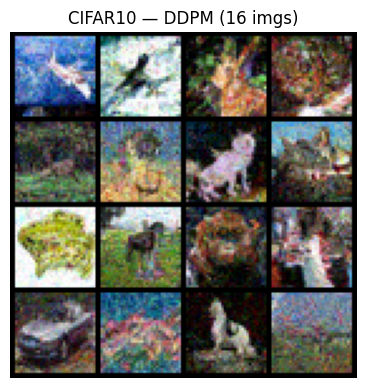

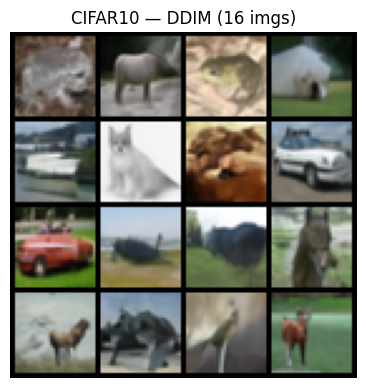

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
# ---- CIFAR10 ----
imgs_ddpm_cifar = batched_generate(ddpm, total=16, steps=50, batch_size=4)  # DDPM plus de steps
imgs_ddim_cifar = batched_generate(ddim, total=16, steps=20,  batch_size=4)  # DDIM rapide

show_grid(imgs_ddpm_cifar, nrow=4, title="CIFAR10 — DDPM (16 imgs)")
show_grid(imgs_ddim_cifar, nrow=4, title="CIFAR10 — DDIM (16 imgs)")

# ---- MNIST (même pipelines pour la démo ; pour mieux coller à MNIST, tu peux charger une pipeline MNIST dédiée si dispo) ----
imgs_ddpm_mnist = batched_generate(ddpm, total=16, steps=50, batch_size=4)
imgs_ddim_mnist = batched_generate(ddim, total=16, steps=20,  batch_size=4)

show_grid(imgs_ddpm_mnist, nrow=4, title="MNIST — DDPM (16 imgs)")
show_grid(imgs_ddim_mnist, nrow=4, title="MNIST — DDIM (16 imgs)")


## Exercise 2 - Output intermediate sampling results (4 points)

Comparing the inference results of DDPM (2 points) and DDIM (2 points) by generating and analyzing their intermediate sampling results. Specifically, you need to run each model through a series of diffusion steps starting from a noisy image, capturing and outputting images at specified intervals to observe how each model refines the image over time. This involves setting up both models, performing inference at regular intervals, and saving these intermediate images to visualize and compare the evolution of image quality between the two models. This task requires to capture and analyze the differences in the sampling processes of DDPM and DDIM, providing insights into their respective performance in transitioning from noise to clearer images. You may also choose different datasets as long as they vary in sizes.

In [ ]:
## TODO

## Exercise 3 - Impact of different number of inference steps (3 points)
DDIM does not change the training process of DDPM but only accelerates the sampling process. You are required to investigate the impact of varying the number of inference steps on the performance of diffusion models. Specifically, you will run experiments with both DDPM and DDIM by changing the number of diffusion steps used during the inference process. For each configuration, you will conduct multiple runs with different number of steps, analyzing how the number of steps affects image quality (3 points) and computational efficiency (3 points). By comparing the results, you will gain insights (1 points) into the trade-offs between the number of steps, image quality, and processing time, thus understanding the balance for effective diffusion model performance. You may also choose different datasets as long as they vary in sizes.

In [ ]:
## TODO

## Exercise 4 - The training of tabular DDPM (4 points)
Train your own small and simple tabular diffusion models following the same steps of the image generation in the tutorial. It should include: model definition, noise and sampling steps specification, choosing the loss function, and the training step. You can get this points by either:
   - train a image DDPM;
   - run the [swiss-roll-2D](https://github.com/joseph-nagel/diffusion-demo/blob/main/notebooks/swissroll.ipynb) tabular diffusion tutorial, first run the scripts/train_ddpm_swissroll.py, ensure you have the right device and specify the numpy version (I have tried both 1.24.0 and 1.26.2 works, some versions not.) save the checkpoints and run the notebooks/swissroll.ipynb. Change something you find interesting and report on it.
   - train the tabular DDPM from scratch, you need to embed the tabular data before feeding into to the networks, normally we concat the continuous value and the one-hot encoding of the discrete values (categorical feature). The network can be the same UNet as images or MLP, e.t.c. If you choose this homework, you get 2 bonus points.

In [ ]:
## TODO